In [161]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score


In [162]:
df = pd.read_csv(r'D:\Diplomado Machine Learning IA\Parte 2\Tarea 2\churn-analysis(1).csv',sep=';')

In [163]:
df

,state,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,total eve minutes,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,415,382-4657,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,415,371-7191,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,415,358-1921,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,408,375-9999,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,415,330-6626,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3328,AZ,415,414-4276,no,yes,36,156.2,77,26.55,215.5,126,18.32,279.1,83,12.56,9.9,6,2.67,2,False
3329,WV,415,370-3271,no,no,0,231.1,57,39.29,153.4,55,13.04,191.3,123,8.61,9.6,4,2.59,3,False
3330,RI,510,328-8230,no,no,0,180.8,109,30.74,288.8,58,24.55,191.9,91,8.64,14.1,6,3.81,2,False
3331,CT,510,364-6381,yes,no,0,213.8,105,36.35,159.6,84,13.57,139.2,137,6.26,5.0,10,1.35,2,False


In [164]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   area code               3333 non-null   int64  
 2   phone number            3333 non-null   object 
 3   international plan      3333 non-null   object 
 4   voice mail plan         3333 non-null   object 
 5   number vmail messages   3333 non-null   int64  
 6   total day minutes       3333 non-null   float64
 7   total day calls         3333 non-null   int64  
 8   total day charge        3333 non-null   float64
 9   total eve minutes       3333 non-null   float64
 10  total eve calls         3333 non-null   int64  
 11  total eve charge        3333 non-null   float64
 12  total night minutes     3333 non-null   float64
 13  total night calls       3333 non-null   int64  
 14  total night charge      3333 non-null   

In [165]:
df_number_corr = df.corr(numeric_only=True)

<Axes: >

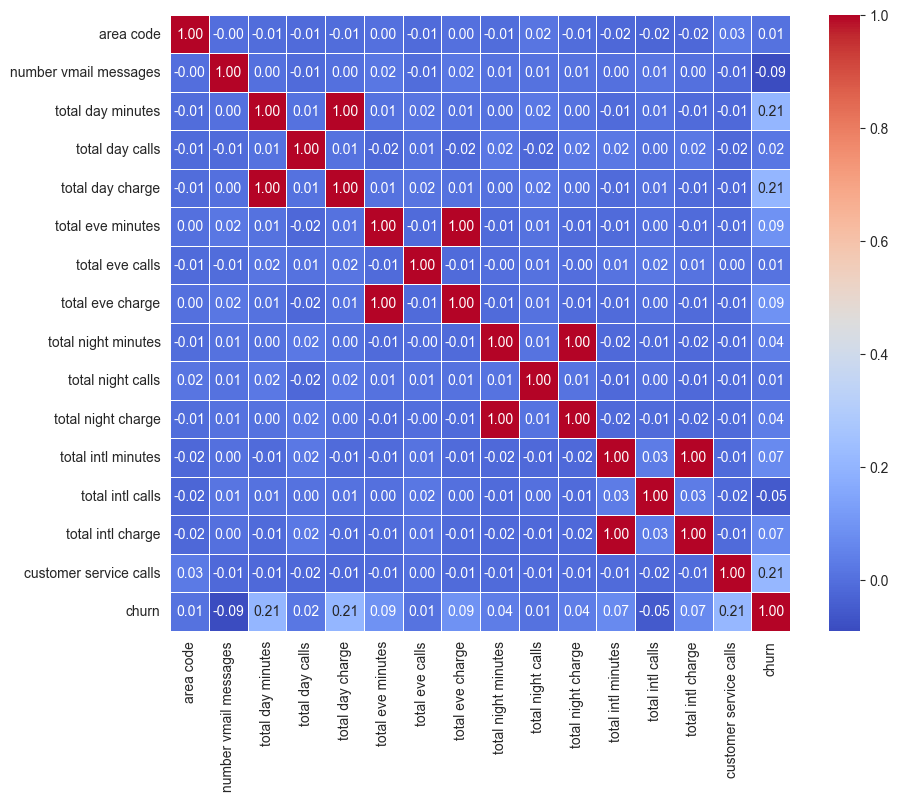

In [166]:
df_number_corr
plt.figure(figsize=(10, 8))
sns.heatmap(df_number_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

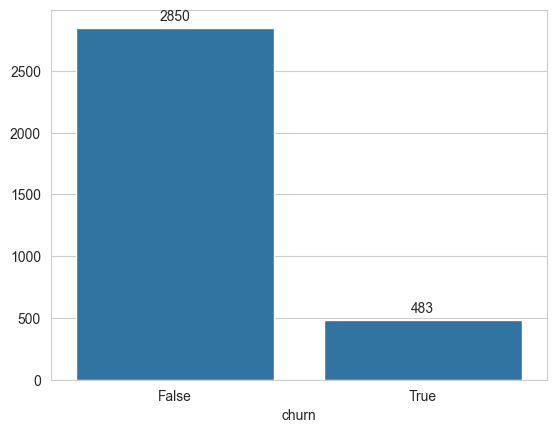

In [167]:
sns.set_style('whitegrid')
xs=sns.countplot(data=df, x='churn')
#xs.set_xlabel("")
xs.set_ylabel("")
for container in xs.containers:
    xs.bar_label(container, padding=3)

In [168]:
numeric_columns = df.select_dtypes(include=['number']).columns.tolist()

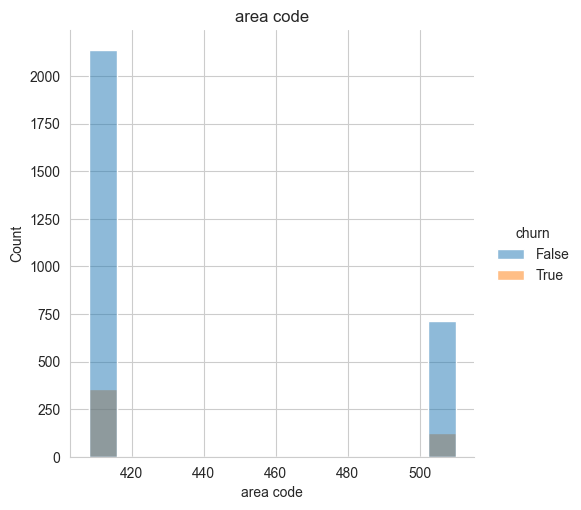

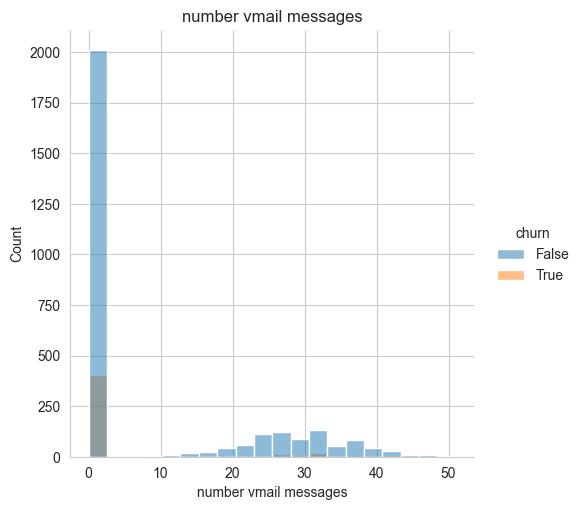

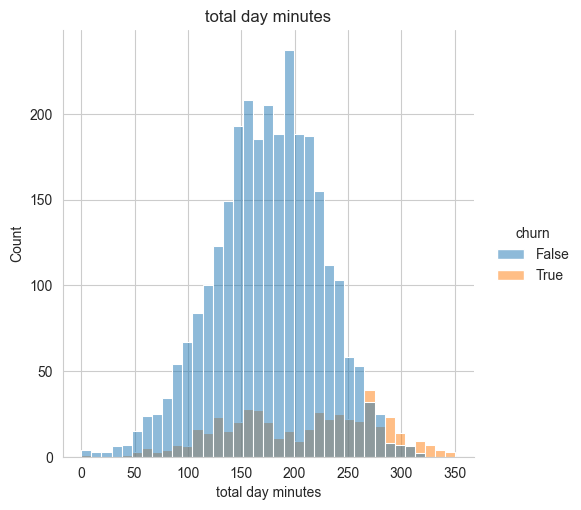

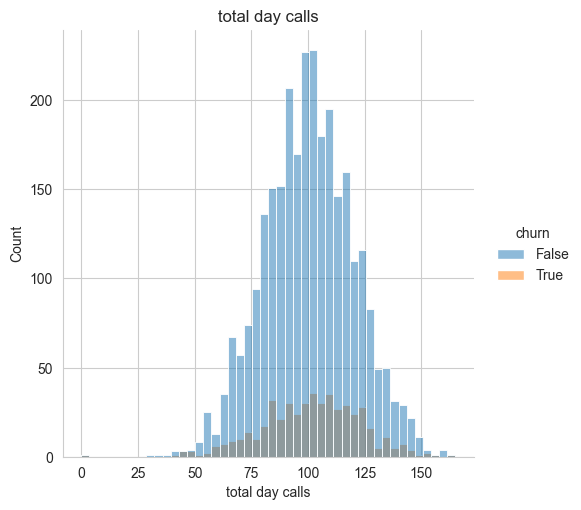

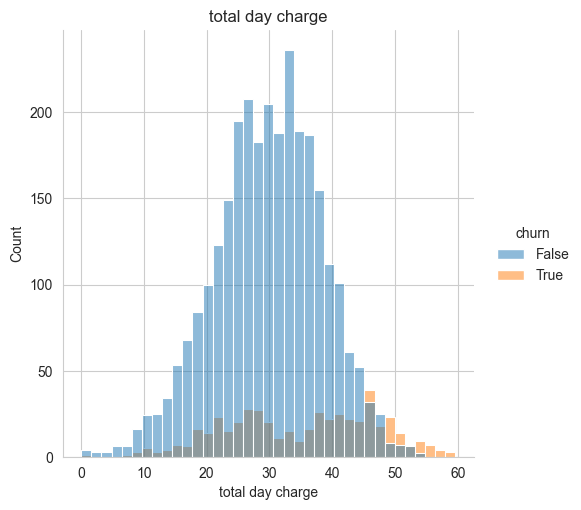

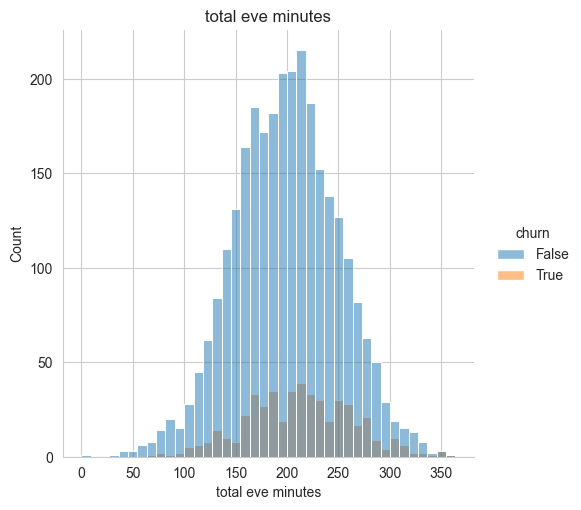

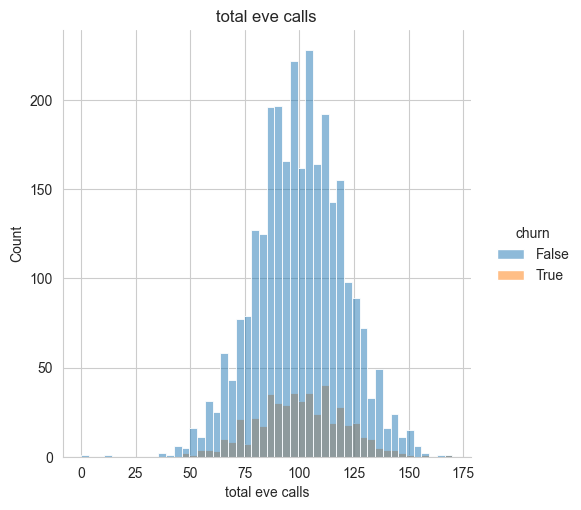

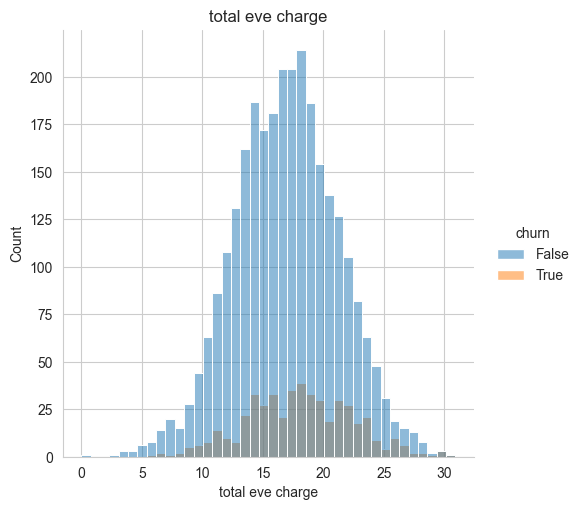

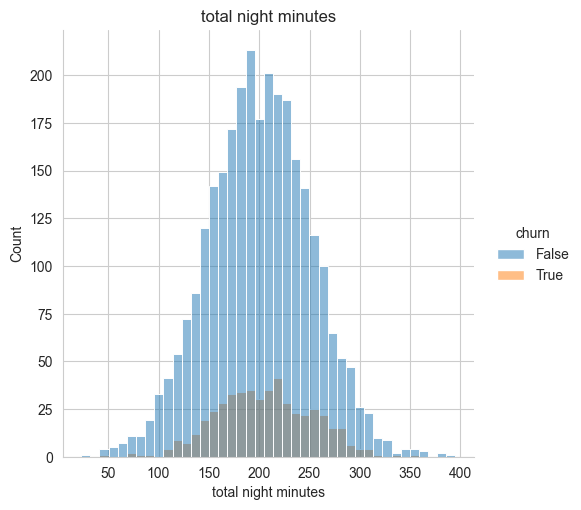

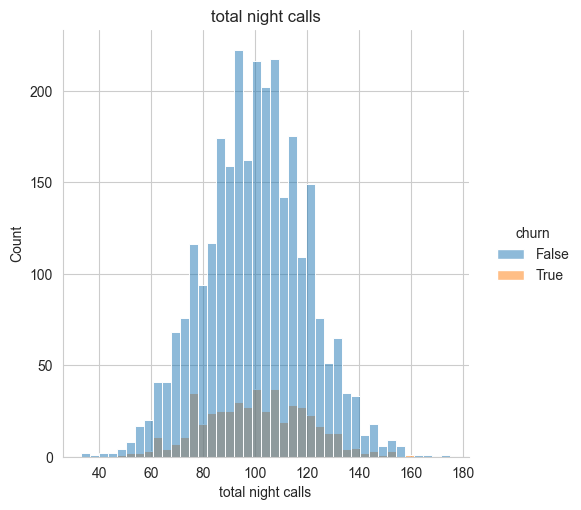

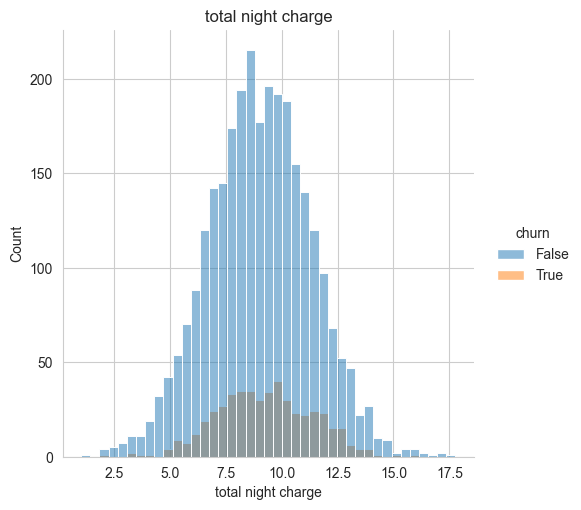

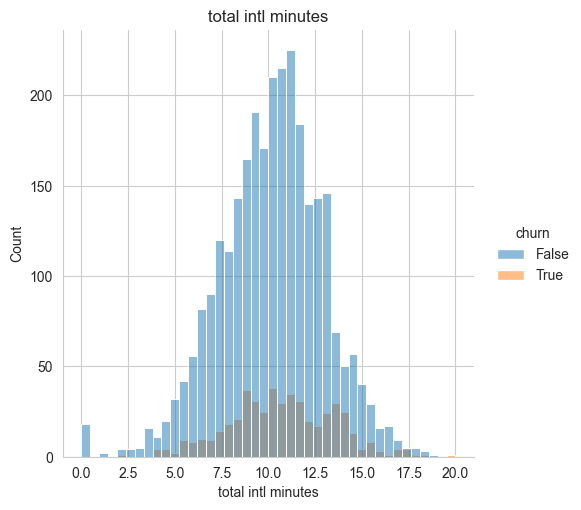

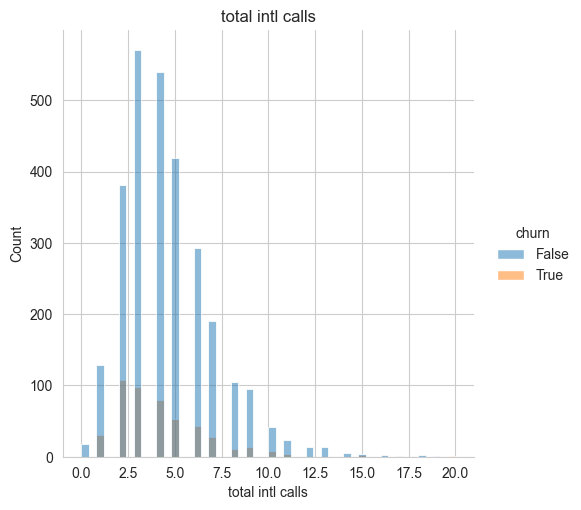

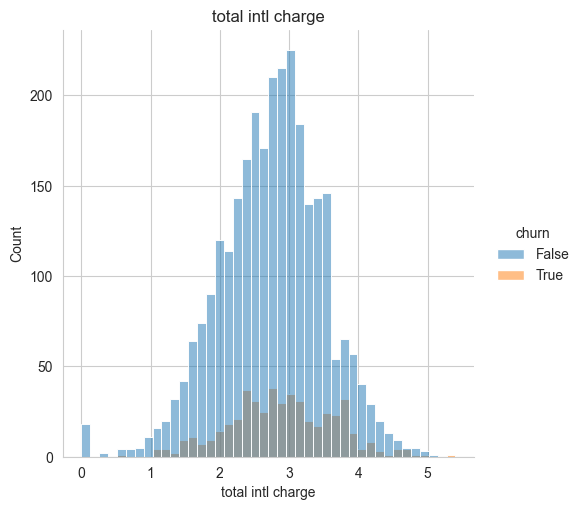

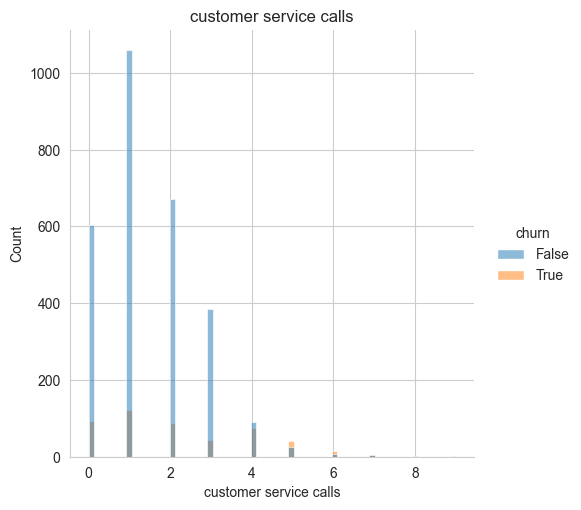

In [169]:
for var in numeric_columns:

    sns.displot(
        data=df,
        x=var,
        hue='churn',
           
    )
    plt.title(f"{var}")

    plt.show()

In [170]:
df.drop(columns=['area code', 'phone number'], inplace=True)

In [171]:
X=df.drop(['churn'], axis=1)
y = df['churn'].map({True:1, False:0})

In [172]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [173]:
numeric_features = X.select_dtypes(include="number").columns
categorical_features = X.select_dtypes(include="object").columns

In [174]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy='mean'))])


categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("encoder", OneHotEncoder(handle_unknown='ignore'))])



preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

## RANDOM FOREST

In [175]:
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        
        random_state=42,
        n_jobs=-1,
        class_weight="balanced",
        n_estimators=300,
        max_depth=5,

         ))
])

In [176]:
random_forest_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [177]:
results = random_forest_pipeline.predict(X_test)
results_proba = random_forest_pipeline.predict_proba(X_test)[:, 1]

In [178]:
# threshold = 0.54

# # Generar predicciones con el nuevo threshold
# results = (results_proba >= threshold).astype(int)

In [179]:
from sklearn.metrics import classification_report, confusion_matrix
print('Accuracy:', accuracy_score(y_test,results))
print('ROC_AUC:' ,roc_auc_score(y_test,results_proba))
print('\nClassification_report')
print(classification_report(y_test, results))
print(confusion_matrix(y_test, results))

Accuracy: 0.8800599700149925
ROC_AUC: 0.9106286953783718

Classification_report
              precision    recall  f1-score   support

           0       0.96      0.89      0.93       566
           1       0.57      0.81      0.67       101

    accuracy                           0.88       667
   macro avg       0.77      0.85      0.80       667
weighted avg       0.90      0.88      0.89       667

[[505  61]
 [ 19  82]]


In [180]:
# from sklearn.metrics import precision_score, recall_score, f1_score
# import pandas as pd

# y_prob = random_forest_pipeline.predict_proba(X_test)[:, 1]

# resultados = []

# for threshold in [0.3, 0.4, 0.5, 0.58,0.6,0.65, 0.7]:

#     y_pred = (y_prob >= threshold).astype(int)

#     resultados.append({
#         "Threshold": threshold,
#         "Precision": precision_score(y_test, y_pred),
#         "Recall": recall_score(y_test, y_pred),
#         "F1": f1_score(y_test, y_pred)
#     })

# print(pd.DataFrame(resultados))

In [181]:
score = cross_val_score(
    random_forest_pipeline,
    X,
    y,
    cv=5,
    scoring="roc_auc",
    n_jobs=1
)
print(f"Cross-validation scores: {score}")
print(f"Mean accuracy: {score.mean():.2f} (+/- {score.std() * 2:.2f})")

Cross-validation scores: [0.90595044 0.85056972 0.93327907 0.91820175 0.91524123]
Mean accuracy: 0.90 (+/- 0.06)


## XGBOOST

In [ ]:
from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
         n_jobs=-1,scale_pos_weight=9
    ))
])



In [206]:
xgb_cv_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [207]:
results_xgb =  xgb_cv_pipeline.predict(X_test)
results_proba_xgb = xgb_cv_pipeline.predict_proba(X_test)[:, 1]

In [212]:
print('Accuracy:', accuracy_score(y_test,results_xgb))
print('ROC AUC:', roc_auc_score(y_test, results_proba_xgb))
print('\nClassification_report')
print(classification_report(y_test, results_xgb))

Accuracy: 0.9175412293853074
ROC AUC: 0.9176783402721898

Classification_report
              precision    recall  f1-score   support

           0       0.97      0.93      0.95       566
           1       0.69      0.84      0.76       101

    accuracy                           0.92       667
   macro avg       0.83      0.89      0.85       667
weighted avg       0.93      0.92      0.92       667



In [217]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_scores = cross_val_score(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

xgb_scores = cross_val_score(
    xgb_cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Random Forest:", rf_scores.mean())
print(f"XGBoost: {xgb_scores.mean():.4f} (+/- {xgb_scores.std() * 2:.4f})")

Random Forest: 0.8959323662248918
XGBoost: 0.9051 (+/- 0.0229)


In [182]:
import h2o
from h2o.automl import H2OAutoML

h2o.init(max_mem_size="10G", nthreads=-1)

Checking whether there is an H2O instance running at http://localhost:54321. connected.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,1 hour 38 mins
H2O_cluster_timezone:,America/Santiago
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.11
H2O_cluster_version_age:,4 months and 21 days
H2O_cluster_name:,H2O_from_python_Rojas_997d6k
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,9.91 Gb
H2O_cluster_total_cores:,12
H2O_cluster_allowed_cores:,12
H2O_cluster_status:,"locked, healthy"


In [183]:
train_pd = X_train.copy()
train_pd["churn"] = y_train

test_pd = X_test.copy()
test_pd["churn"] = y_test

train = h2o.H2OFrame(train_pd)
test = h2o.H2OFrame(test_pd)

assert train.nrows == len(X_train)
assert test.nrows == len(X_test)
print(f"Misma partición que Random Forest: train={train.nrows}, test={test.nrows}")

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Misma partición que Random Forest: train=2666, test=667


In [184]:
train['churn']=train['churn'].asfactor()
test['churn'] = test['churn'].asfactor()

In [185]:
predictores = list(X_train.columns)

aml = H2OAutoML(
    max_models=5,
    nfolds=3,
    sort_metric="AUC",
    seed=42,
    include_algos=["GLM", "DRF", "GBM", "StackedEnsemble"]
)

aml.train(
    x=predictores,
    y="churn",
    training_frame=train
)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%


key,value
Stacking strategy,cross_validation
Number of base models (used / total),3/5
# GBM base models (used / total),2/3
# DRF base models (used / total),0/1
# GLM base models (used / total),1/1
Metalearner algorithm,GLM
Metalearner fold assignment scheme,Random
Metalearner nfolds,3
Metalearner fold_column,None
Custom metalearner hyperparameters,None


In [186]:
print(aml.leaderboard)
mejor_modelo = aml.leader
print("Mejor modelo:", mejor_modelo.model_id)

model_id                                                      auc    logloss     aucpr    mean_per_class_error      rmse        mse
StackedEnsemble_AllModels_1_AutoML_6_20261013_110603     0.903959   0.193006  0.822442                0.140089  0.220044  0.0484193
StackedEnsemble_BestOfFamily_1_AutoML_6_20261013_110603  0.903297   0.19424   0.822132                0.132897  0.220573  0.0486524
GBM_2_AutoML_6_20261013_110603                           0.902311   0.200704  0.820119                0.133116  0.224596  0.0504435
GBM_3_AutoML_6_20261013_110603                           0.90133    0.210343  0.802193                0.150355  0.233831  0.0546771
DRF_1_AutoML_6_20261013_110603                           0.900779   0.398613  0.820621                0.137257  0.238036  0.0566613
GBM_1_AutoML_6_20261013_110603                           0.885047   0.257846  0.676052                0.181628  0.271481  0.0737017
GLM_1_AutoML_6_20261013_110603                           0.805395   0.331232

In [187]:
rendimiento = mejor_modelo.model_performance(test)
print("AUC en test:", rendimiento.auc())

AUC en test: 0.9283752580205018


In [188]:
predicciones = mejor_modelo.predict(test[predictores])
predicciones.head()

stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%


predict,p0,p1
0,0.922757,0.0772428
0,0.991206,0.00879376
1,0.0454388,0.954561
0,0.972643,0.0273574
0,0.982221,0.0177792
0,0.975116,0.024884
0,0.939035,0.0609646
0,0.98684,0.0131598
0,0.975804,0.0241961
0,0.978511,0.0214894
